# 02 - Anomaly model: global model + personal baselines

Uses the clean data from notebook 01.

The idea again:
- a **new user** has no history, so we compare them with everyone else (the **global model**)
- once they have enough days of a signal, we compare them with **their own normal** (the **personal baseline**)
- between the two we blend, so there's no sudden jump

The problem is we have **no labels**. Nobody marked "this day was abnormal". So we test it in two ways:
1. **inject fake anomalies** (an illness-like pattern) into real days and see what gets caught
2. check whether flagged days line up with people **saying** they felt tense or tired

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from healthnexus_ml import anomaly as an
from healthnexus_ml.preprocessing import PROCESSED_DIR

pd.set_option('display.width', 160)
plt.rcParams['figure.figsize'] = (10, 4)

df = pd.read_csv(PROCESSED_DIR / 'daily_clean.csv', parse_dates=['date'])
df.shape

(4766, 31)

## 1. Train / test split by user

We split by **user**, not by day. If we split by day, the global model would already have seen the test users' other days, which would make it look better than it really is for a brand new user.

15 users go to test, 56 to train.

In [2]:
users = np.array(sorted(df['user_id'].unique()))
np.random.default_rng(0).shuffle(users)
test_users = users[:15]

train = df[~df['user_id'].isin(test_users)]
test = df[df['user_id'].isin(test_users)].sort_values(['user_id', 'date']).copy()
print('train:', train['user_id'].nunique(), 'users,', len(train), 'days')
print('test: ', test['user_id'].nunique(), 'users,', len(test), 'days')

train: 56 users, 3414 days
test:  15 users, 1352 days


## 2. Why a personal baseline at all?

If everyone's "normal" was about the same, one global model would be enough. So we compare the **spread between users** (how different people's averages are) with the **spread within a user** (how much one person changes day to day).

In [3]:
between = df.groupby('user_id')[an.FEATS].median().std()
within = df.groupby('user_id')[an.FEATS].std().median()
spread = pd.DataFrame({'between users': between, 'within a user': within})
spread['ratio'] = spread['between users'] / spread['within a user']
spread.round(2).sort_values('ratio', ascending=False)

,between users,within a user,ratio
resting_hr,6.83,2.21,3.09
hrv_rmssd,18.69,6.65,2.81
breathing_rate,2.27,0.83,2.73
sleep_efficiency,5.24,2.44,2.14
sleep_hr,6.80,4.37,1.56
skin_temp,0.67,0.49,1.37
sedentary_minutes,196.63,198.69,0.99
sleep_minutes,64.61,75.57,0.85
steps,3240.07,4148.03,0.78
very_active_minutes,14.74,22.63,0.65


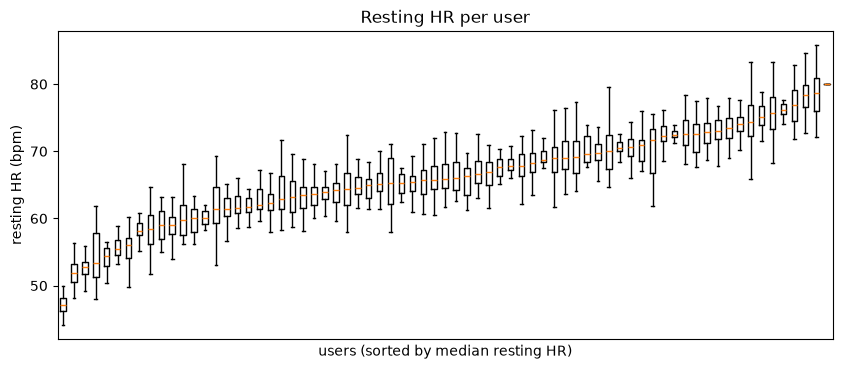

In [4]:
order = df.groupby('user_id')['resting_hr'].median().sort_values().index
data = [df.loc[df['user_id'] == u, 'resting_hr'].dropna() for u in order]
plt.boxplot(data, showfliers=False)
plt.xticks([])
plt.xlabel('users (sorted by median resting HR)')
plt.ylabel('resting HR (bpm)')
plt.title('Resting HR per user')
plt.show()

This is what we hoped to see. For **resting HR, HRV and breathing rate, people differ from each other about 3x more than they change day to day**. So a global model mostly learns "who is this person" and not "is today unusual". Someone's normal resting HR can be anywhere from ~55 to ~80 bpm (see the boxplot).

For steps, activity and sleep minutes it's the other way round: day-to-day changes are bigger than the differences between people. A personal baseline doesn't add much there, which is another reason we keep activity out of the personal score.

## 3. Global model (Isolation Forest)

For the global model we use an **Isolation Forest**. It's unsupervised, so it doesn't need labels. It works by randomly splitting the data: unusual points get isolated in fewer splits.

Before training:
- each feature is standardised with the population **median and MAD** (median absolute deviation) instead of mean/std, because the data has outliers and the mean gets pulled around by them
- missing values are filled with 0 after standardising, i.e. "same as the median person". Isolation Forest can't handle NaN, and since about half the days have no HRV we can't just drop them

`contamination=0.03` means we expect roughly 3% of days to be unusual. The raw forest score doesn't mean much on its own, so we turn it into a 0-1 score where 0.5 = top 3% of training days.

flagged on train: 0.032


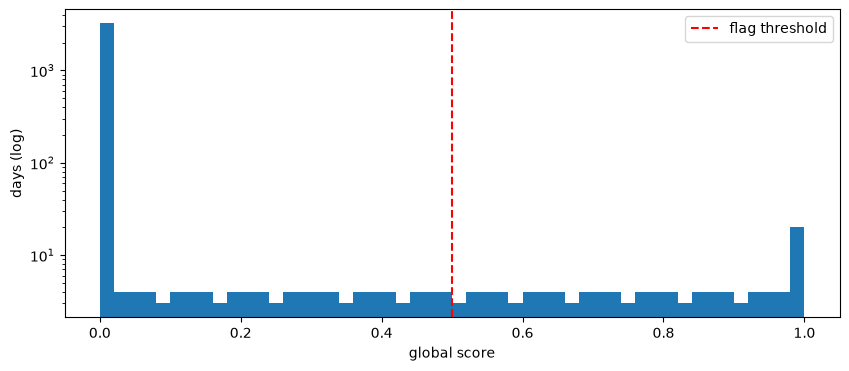

In [5]:
model = an.GlobalModel().fit(train)
train_scores = model.score(train)
print('flagged on train:', (train_scores >= an.FLAG_THRESHOLD).mean().round(3))

plt.hist(train_scores, bins=50)
plt.axvline(an.FLAG_THRESHOLD, color='red', ls='--', label='flag threshold')
plt.yscale('log'); plt.xlabel('global score'); plt.ylabel('days (log)'); plt.legend()
plt.show()

## 4. Personal baselines

For each user and each signal we keep a rolling **median** (their normal) and **MAD** (how much they usually vary) over their last 60 valid days. **Only earlier days** are used, never the day being scored, otherwise an abnormal day would be partly compared with itself.

Then each day gets a personal z-score per signal: `(today - their median) / their spread`.

Two small things we had to deal with:
- some users are very regular, so their MAD is close to 0 and the z-scores blew up. We set a minimum spread of 1/4 of the population spread
- **steps and activity are left out of the personal score.** In our first try we took the biggest z-score over all 10 signals and it flagged ~25% of normal days, nearly always because of steps. Activity depends on what someone chose to do that day (gym, lazy Sunday), not on their health. So the personal score only uses the body signals (resting HR, HRV, sleep HR, breathing rate, skin temp), combined as an RMS so one slightly-off signal doesn't trigger a flag but several together do

**Blending:** the personal weight for a signal goes from 0 to 1 between 7 and 21 valid days of history.

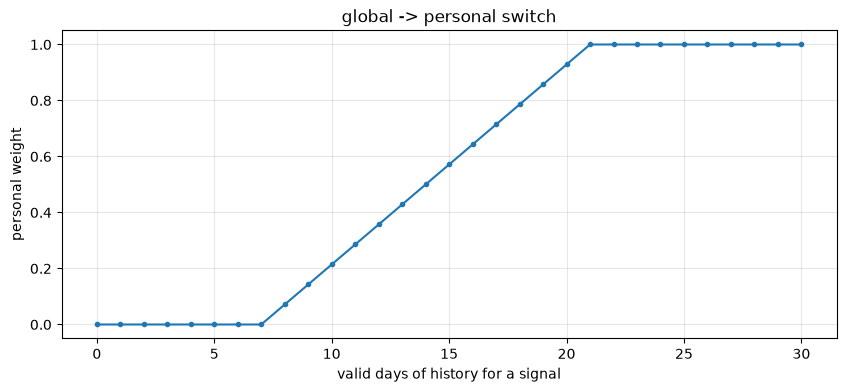

In [6]:
n = np.arange(0, 31)
plt.plot(n, an.personal_weight(n), marker='.')
plt.xlabel('valid days of history for a signal'); plt.ylabel('personal weight')
plt.title('global -> personal switch'); plt.grid(alpha=.3)
plt.show()

Here's one test user (the one with the most days), with their personal resting HR baseline:

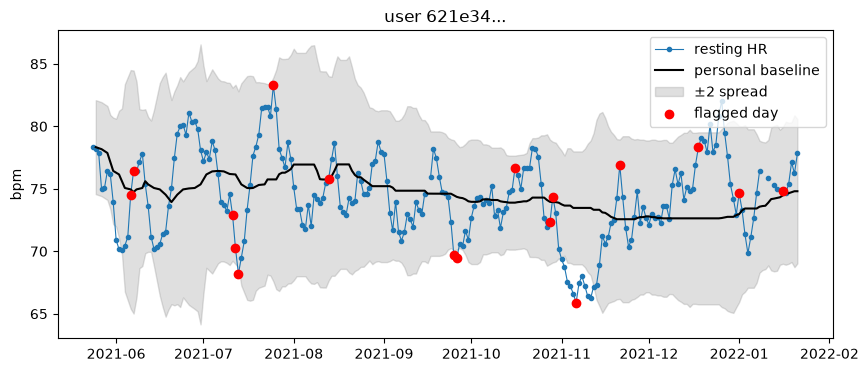

In [7]:
scored = an.score_days(test, model)
base = an.personal_baselines(test, model.mad_)

u = test.groupby('user_id').size().idxmax()
m = test['user_id'] == u
d, b, s = test[m], base[m], scored[m]

plt.plot(d['date'], d['resting_hr'], '.-', lw=.8, label='resting HR')
plt.plot(d['date'], b['resting_hr_base'], color='k', label='personal baseline')
plt.fill_between(d['date'], b['resting_hr_base'] - 2 * b['resting_hr_spread'],
                 b['resting_hr_base'] + 2 * b['resting_hr_spread'], color='grey', alpha=.25, label='±2 spread')
plt.scatter(d.loc[s['flag'], 'date'], d.loc[s['flag'], 'resting_hr'], color='red', zorder=3, label='flagged day')
plt.legend(); plt.ylabel('bpm'); plt.title(f'user {u[:6]}...')
plt.show()

In [8]:
s.loc[s['flag']].set_index('date')[['score', 'global_score', 'personal_score', 'personal_weight', 'reason', 'reason_z']].round(2).head(10)

,score,global_score,personal_score,personal_weight,reason,reason_z
date,,,,,,
2021-06-06,0.78,0.92,0.00,0.14,sleep_efficiency,-7.90
2021-06-07,0.73,0.85,0.00,0.14,breathing_rate,3.29
2021-07-11,1.00,0.00,1.00,1.00,breathing_rate,-6.58
2021-07-12,1.00,0.00,1.00,1.00,breathing_rate,-6.84
2021-07-13,1.00,0.00,1.00,1.00,breathing_rate,-7.87
2021-07-25,1.00,0.94,1.00,1.00,breathing_rate,12.37
2021-08-13,1.00,0.42,1.00,1.00,breathing_rate,11.92
2021-09-25,0.58,0.00,0.58,1.00,sedentary_minutes,7.01
2021-09-26,0.76,0.00,0.76,1.00,very_active_minutes,7.64


The `reason` column is the signal that's furthest from normal. The app can use it to say something like *"your resting heart rate is higher than usual"* instead of just "anomaly".

## 5. How often does it flag normal data?

On the test users with **no fake anomalies**, a flag is not necessarily wrong (people really do get sick), but if it flags too much nobody will trust it.

In [9]:
flag_rates = scored[['global_score', 'personal_score', 'score']].ge(an.FLAG_THRESHOLD).mean()
flag_rates.rename('share of days flagged').round(3)

global_score      0.016
personal_score    0.085
score             0.060
Name: share of days flagged, dtype: float64

## 6. Test with injected anomalies

We take real test days (after each user's 10th day) and make 10% of them look like the start of an illness. This is roughly what wearable studies report for things like flu or COVID: resting HR up, HRV down, sleeping HR up, skin temperature up.

We do it at three strengths. The "mild" one is deliberately small, about what a normal day-to-day change looks like for some people.

In [10]:
SEVERITY = {
    'mild':     dict(resting_hr=4,  sleep_hr=4,  hrv_rmssd=0.85, skin_temp=0.4),
    'moderate': dict(resting_hr=8,  sleep_hr=7,  hrv_rmssd=0.65, skin_temp=0.8),
    'strong':   dict(resting_hr=12, sleep_hr=10, hrv_rmssd=0.50, skin_temp=1.2),
}

def inject(d, change, frac=0.1, seed=1):
    d = d.copy()
    idx = d[d['day_index'] > 10].sample(frac=frac, random_state=seed).index
    d.loc[idx, 'resting_hr'] += change['resting_hr']
    d.loc[idx, 'sleep_hr'] += change['sleep_hr']
    d.loc[idx, 'hrv_rmssd'] *= change['hrv_rmssd']
    d.loc[idx, 'skin_temp'] += change['skin_temp']
    return d, idx

rows = []
for name, change in SEVERITY.items():
    d_inj, idx = inject(test, change)
    s_inj = an.score_days(d_inj, model)
    normal = scored.drop(idx)  # same days, without injection
    for col in ['global_score', 'personal_score', 'score']:
        y = np.r_[np.ones(len(idx)), np.zeros(len(normal))]
        x = np.r_[s_inj.loc[idx, col], normal[col]]
        rows.append({'severity': name, 'model': col,
                     'detected': (s_inj.loc[idx, col] >= an.FLAG_THRESHOLD).mean(),
                     'false flags': (normal[col] >= an.FLAG_THRESHOLD).mean(),
                     'ROC AUC': roc_auc_score(y, x)})

results = pd.DataFrame(rows)
results.round(3)

,severity,model,detected,false flags,ROC AUC
0,mild,global_score,0.025,0.017,0.517
1,mild,personal_score,0.275,0.080,0.650
2,mild,score,0.208,0.055,0.667
3,moderate,global_score,0.100,0.017,0.571
4,moderate,personal_score,0.550,0.080,0.828
5,moderate,score,0.450,0.055,0.838
6,strong,global_score,0.167,0.017,0.613
7,strong,personal_score,0.783,0.080,0.897
8,strong,score,0.683,0.055,0.900


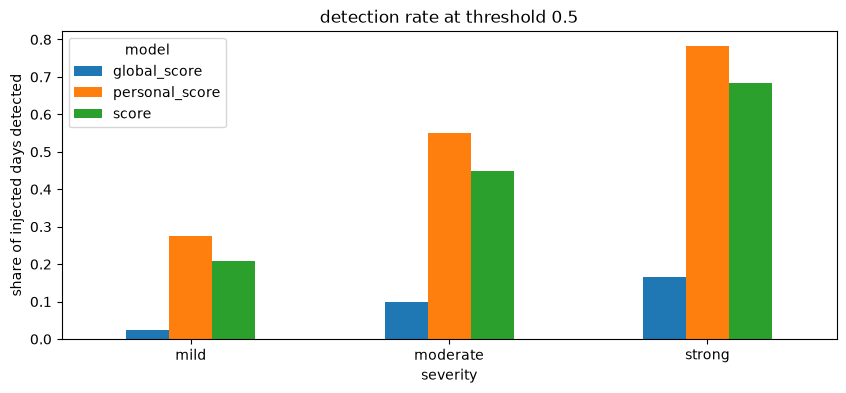

In [11]:
results.pivot(index='severity', columns='model', values='detected').loc[list(SEVERITY)].plot.bar(rot=0)
plt.ylabel('share of injected days detected'); plt.title('detection rate at threshold 0.5')
plt.show()

Main result:
- the **global model barely beats guessing** (ROC AUC 0.52-0.61). A +8 bpm jump usually still looks normal compared to other people
- **personal baselines catch much more**: 55% of moderate and 78% of strong anomalies, AUC up to 0.90
- the **blended score** has the best AUC overall and fewer false flags (5.5% vs 8%) than pure personal, because the global part helps early on. It detects a bit less at threshold 0.5 since some injected days fall in a user's first weeks

The cost is false flags: personal flags ~8% of normal days vs 1.6% for global. For a health app that's probably too many alerts, see the summary for ideas.

### Who does the global model miss?

Our guess was that the global model misses people whose normal is far from average. Example: someone with a resting HR of 55 who goes up to 63 is still "normal" compared to everyone else, but it's a big change for them.

In [12]:
d_inj, idx = inject(test, SEVERITY['moderate'])
s_inj = an.score_days(d_inj, model)
hits = s_inj.loc[idx].join(test.loc[idx, ['resting_hr']].rename(columns={'resting_hr': 'orig_rhr'}))
user_rhr = test.groupby('user_id')['resting_hr'].median()
hits['user_median_rhr'] = hits['user_id'].map(user_rhr)
hits['rhr_group'] = pd.qcut(hits['user_median_rhr'], 3, labels=['low RHR users', 'mid', 'high RHR users'])

by_group = hits.groupby('rhr_group', observed=True)[['global_score', 'personal_score', 'score']].apply(
    lambda g: (g >= an.FLAG_THRESHOLD).mean())
by_group.round(2)

,global_score,personal_score,score
rhr_group,,,
low RHR users,0.00,0.60,0.47
mid,0.02,0.70,0.57
high RHR users,0.30,0.32,0.30


For **low and mid resting-HR users the global model caught basically nothing** (0-2%), while personal caught 60-70%. That's exactly the case we expected: their raised HR is still "normal" compared to everyone else.

The global model only catches anything for the high-RHR group (30%), where +8 bpm pushes them past the population range. We didn't expect personal to do worse on that group (32%). Our guess is that those users vary more day to day, so their personal spread is wider and the same +8 bpm is a smaller z-score for them. Only 15 test users though, so each group is just 5 people.

### Does history help? (detection vs personal weight)

Split the injected days by how far the user is through the global → personal switch.

In [13]:
hits['stage'] = pd.cut(hits['personal_weight'], [-0.01, 0.0, 0.99, 1.0], labels=['global only', 'blending', 'fully personal'])
hits.groupby('stage', observed=True).agg(days=('score', 'size'),
                                         detected=('flag', 'mean')).round(2)

,days,detected
stage,,
global only,10,0.00
blending,27,0.22
fully personal,83,0.58


Detection goes up as a user builds history: **0% on global-only days â†’ 22% while blending â†’ 58% once fully personal**. This is the "baseline improves as data increases" idea working. (Only 10 injected days are in the global-only stage because we injected after day 10, so that number is rough.)

## 7. Sanity check against how people felt

LifeSnaps has short mood check-ins. If the model picks up something real, flagged days should come up a bit more often on days people said they felt **TENSE/ANXIOUS** or **TIRED**. This is weak evidence (moods were only reported on some days, and stress doesn't always show up in the body), but it's the only "real" signal we have.

We use the test users only, so the global model hasn't seen them.

In [14]:
mood = scored.join(test[['TENSE/ANXIOUS', 'TIRED', 'HAPPY', 'RESTED/RELAXED']])
mood['bad_mood'] = (mood['TENSE/ANXIOUS'] + mood['TIRED']) > 0
mood['good_mood'] = (mood['HAPPY'] + mood['RESTED/RELAXED']) > 0
print('days with a bad mood report :', mood['bad_mood'].sum())
print('days with a good mood report:', mood['good_mood'].sum())

pd.DataFrame({
    'bad mood days': mood.loc[mood['bad_mood'], ['global_score', 'score']].mean(),
    'good mood days': mood.loc[mood['good_mood'], ['global_score', 'score']].mean(),
    'all days': mood[['global_score', 'score']].mean(),
}).round(3)

days with a bad mood report : 156
days with a good mood report: 166


,bad mood days,good mood days,all days
global_score,0.004,0.011,0.017
score,0.088,0.096,0.107


**No real relationship.** Bad mood days don't get higher scores than good mood days (0.088 vs 0.096 blended). So we can't claim the model detects stress from this data.

That doesn't mean the model is wrong. The mood check-ins are about mental state, which often doesn't show up in resting HR or temperature the next morning, and they're sparse (156 bad-mood days). We report it as a negative result rather than leaving it out.

## 8. Train the final global model on everyone and save it

For the app we train the global model on all 71 users (the split above was only for testing). The personal baselines aren't saved anywhere because they're calculated from each user's own history when scoring.

In [15]:
from healthnexus_ml import train
train.main()

trained on 4766 days from 71 users -> C:\Health_Nexus\ml\models\global_anomaly.joblib


## Summary

- People's "normal" differs a lot for body signals (between-user spread ~3x within-user for resting HR/HRV/breathing), so **a personal baseline is needed**. The global model alone can't see changes that are big for one person but normal for the population
- **Global model** (Isolation Forest): used for new users and as a fallback. Weak at catching individual changes (AUC â‰¤ 0.61)
- **Personal baseline** (rolling median/MAD, past days only, body signals only): AUC up to 0.90 on injected illness-like anomalies
- **Blend**: global â†’ personal between 7 and 21 days of history per signal. Detection rises from 0% â†’ 58% as history builds up
- Mood check-ins showed no link to flags, so this is a negative result

**Limitations**
- the anomalies are synthetic, so real illness might look different
- ~8% false flags with personal baselines is a lot for alerts
- only 15 test users

**Next / ideas**
- only alert when a day is flagged **2+ days in a row** (illness usually lasts several days, noise doesn't), which should cut false flags a lot
- tune `MIN_DAYS`, `FULL_DAYS` and the threshold
- hook `score_days` into the backend so each user's new data is scored when it's uploaded